# SmolVLM-256M: CUDA Graph Decoding

This notebook runs SmolVLM-256M on one image with a CUDA graph for the decode steps. It prints the answer.

In [ ]:
import copy
import gc
import json
import re
import subprocess
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor, StaticCache
from transformers.modeling_outputs import BaseModelOutput

ROOT = next(p for p in (Path(".."), Path("."), Path("/content/edge-ai-smol-lvm-250-optimization"))
            if (p / "frame.jpg").exists())
IMAGE = ROOT / "frame.jpg"
MODEL_ID = "HuggingFaceTB/SmolVLM-256M-Instruct"
PROMPT = "Describe any visible defects."
PREPROCESS = {"default": (None, "cpu"), "slow": (False, "cpu"), "fast-cpu": (True, "cpu"), "fast-gpu": (True, "cuda")}


def timed(fn):
    torch.cuda.synchronize()
    t = time.perf_counter()
    out = fn()
    torch.cuda.synchronize()
    return out, (time.perf_counter() - t) * 1e3


def mean_ms(fn, runs=5):
    fn()
    torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(runs):
        fn()
        torch.cuda.synchronize()
    return (time.perf_counter() - t) * 1e3 / runs


def until_eos(ids, eos):
    for i, t in enumerate(ids):
        if t in eos:
            return ids[:i]
    return ids


def set_attn(model, impl):
    if hasattr(model, "set_attn_implementation"):
        model.set_attn_implementation(impl)
    else:
        for c in (model.config.text_config, model.config.vision_config):
            c._attn_implementation = impl


def load(attn=None, fast=None):
    kw = {} if attn is None else {"attn_implementation": attn}
    proc = AutoProcessor.from_pretrained(MODEL_ID, **({} if fast is None else {"use_fast": fast}))
    model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, dtype=torch.float16, **kw).to("cuda").eval()
    return model, proc


def eos_ids(tok):
    return {tok.eos_token_id, tok.convert_tokens_to_ids("<end_of_utterance>")}


def chat_text(proc, prompt):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    return proc.apply_chat_template(msgs, add_generation_prompt=True)


def make_inputs(proc, image, prompt, image_device="cpu", size=None, extra=None):
    img = Image.open(image).convert("RGB") if isinstance(image, (str, Path)) else image
    dev = {} if image_device == "cpu" else {"device": image_device}
    ik = {**({} if size is None else {"size": {"longest_edge": size}}), **dev, **(extra or {})}
    text = chat_text(proc, prompt)
    try:
        out = proc(text=text, images=[img], return_tensors="pt", images_kwargs=ik)
    except (TypeError, ValueError):
        out = proc(text=text, images=[img], return_tensors="pt", **ik)
    out = out.to("cuda")
    out["pixel_values"] = out["pixel_values"].to(torch.float16)
    return out


def bare_generate(model, inputs, k, stop=True):
    extra = {} if stop else {"min_new_tokens": k}
    with torch.inference_mode():
        return model.generate(**inputs, max_new_tokens=k, do_sample=False, **extra)


class GraphDecoder:
    def __init__(self, model, max_new=64, max_len=4096, own_mask=False):
        self.model, self.max_new, self.max_len = model, max_new, max_len
        self.cache = StaticCache(config=model.config.text_config, max_cache_len=max_len)
        dev = model.device
        self.ids = torch.zeros(1, 1, dtype=torch.long, device=dev)
        self.pos = torch.zeros(1, dtype=torch.long, device=dev)
        self.idx = torch.zeros(1, dtype=torch.long, device=dev)
        self.out = torch.zeros(max_new, dtype=torch.long, device=dev)
        self.graph = None
        self.steps = max_new
        self.own_mask = own_mask or model.config.text_config._attn_implementation == "eager"

    def mask(self):
        allowed = torch.arange(self.max_len, device=self.pos.device) <= self.pos[:, None]
        dt = self.model.dtype
        return ((~allowed).to(dt) * torch.finfo(dt).min)[:, None, None, :]

    def step(self):
        extra = {"attention_mask": self.mask()} if self.own_mask else {}
        h = self.model.model.text_model(
            input_ids=self.ids, cache_position=self.pos, past_key_values=self.cache, use_cache=True, **extra
        ).last_hidden_state
        nxt = self.model.lm_head(h[:, -1]).argmax(-1, keepdim=True)
        self.ids.copy_(nxt)
        self.out.index_copy_(0, self.idx, nxt.view(1))
        self.pos.add_(1)
        self.idx.add_(1)

    @torch.inference_mode()
    def capture(self):
        s = torch.cuda.Stream()
        s.wait_stream(torch.cuda.current_stream())
        with torch.cuda.stream(s):
            for _ in range(3):
                self.pos.fill_(self.max_len - 1)
                self.idx.zero_()
                self.step()
        torch.cuda.current_stream().wait_stream(s)
        self.pos.fill_(self.max_len - 1)
        self.idx.zero_()
        self.graph = torch.cuda.CUDAGraph()
        with torch.cuda.graph(self.graph):
            self.step()

    @torch.inference_mode()
    def prefill(self, inputs):
        self.cache.reset()
        n = inputs["input_ids"].shape[1]
        logits = self.model(
            **inputs, past_key_values=self.cache, use_cache=True,
            cache_position=torch.arange(n, device=self.model.device),
        ).logits
        first = logits[:, -1].argmax(-1, keepdim=True)
        self.ids.copy_(first)
        self.pos.fill_(n)
        self.idx.zero_()
        return first

    @torch.inference_mode()
    def decode(self, use_graph=True, eos=None):
        self.steps = self.max_new
        for i in range(self.max_new):
            if use_graph:
                self.graph.replay()
            else:
                self.step()
            if eos and self.ids.item() in eos:
                self.steps = i + 1
                break
        return self.out.clone()

    def generate(self, inputs, eos, use_graph=True):
        first = self.prefill(inputs)
        ids = torch.cat([first.view(1), self.decode(use_graph, eos)]).tolist()
        return until_eos(ids, eos)


def time_decode(dec, inputs, eos, runs=5, use_graph=True, stop=False):
    pre, dec_ms, ids = [], [], None
    for i in range(runs + 1):
        first, p = timed(lambda: dec.prefill(inputs))
        out, d = timed(lambda: dec.decode(use_graph, eos if stop else None))
        if i:
            pre.append(p)
            dec_ms.append(d)
        ids = until_eos(torch.cat([first.view(1), out]).tolist(), eos)
    return {"prefill_ms": float(np.mean(pre)), "decode_ms": float(np.mean(dec_ms)), "steps": dec.steps, "ids": ids}


def fit_len(n, max_new):
    return -(-(n + max_new + 1) // 64) * 64

In [ ]:
model, proc = load()
inputs = make_inputs(proc, IMAGE, PROMPT)
dec = GraphDecoder(model, 64, 4096)
dec.capture()
ids = dec.generate(inputs, eos_ids(proc.tokenizer))
print(proc.tokenizer.decode(ids, skip_special_tokens=True))

## Log of previous runs

The cells below are the earlier notebook with their outputs. They call the scripts that were replaced by the code above, so they are not run again.

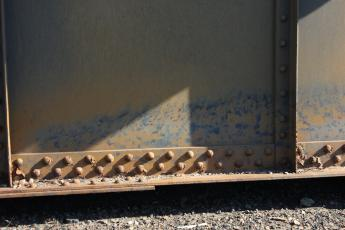

In [1]:
REPO = "./edge-ai-smol-lvm-250-optimization"
from IPython.display import Image
Image(f"{REPO}/frame.jpg")

In [2]:
import sys
sys.path.append(REPO)
from smolvlm_cuda_graphs import PROMPT
print(PROMPT)

Describe any visible defects.


In [17]:
!python ./edge-ai-smol-lvm-250-optimization/smolvlm_cuda_graphs.py ./edge-ai-smol-lvm-250-optimization/frame.jpg

Loading weights: 100% 471/471 [00:00<00:00, 1281.25it/s]
 There are no visible defects in the image.


In [6]:
!python ./edge-ai-smol-lvm-250-optimization/bench.py --image ./edge-ai-smol-lvm-250-optimization/frame.jpg

Loading weights: 100% 471/471 [00:00<00:00, 1124.55it/s]
prompt tokens: 875 | max_len: 4096
 bare: prefill  279.2 ms | decode 40.24 ms/token |   24.9 tok/s
eager: prefill  269.3 ms | decode 32.34 ms/token |   30.9 tok/s
graph: prefill  274.0 ms | decode 16.69 ms/token |   59.9 tok/s
identical outputs (eager vs graph): True
bare matches graph up to EOS: True


In [8]:
import subprocess

for n in [512, 1024, 2048]:
    r = subprocess.run(
        ["python", f"{REPO}/bench.py", "--image", f"{REPO}/frame.jpg", "--max-len", str(n)],
        capture_output=True, text=True,
    )
    print(f"--- max_len {n}")
    print(r.stdout if r.returncode == 0 else r.stderr.strip().splitlines()[-1])

--- max_len 512
AssertionError: prompt 875 + 64 new tokens do not fit max_len 512
--- max_len 1024
memory after load: RAM peak 1822 MB | VRAM allocated 497 MB, peak 497 MB, reserved 520 MB
prompt tokens: 875 | max_len: 1024
preprocessing (CPU):
  JPEG decode                                0.7 ms
  tile + normalize                         308.4 ms
  tokenize                                   0.1 ms
  make_inputs total (incl. copy to GPU)    324.5 ms
 bare: prefill  286.6 ms | decode 39.64 ms/token |   25.2 tok/s
eager: prefill  285.2 ms | decode 31.76 ms/token |   31.5 tok/s
graph: prefill  285.6 ms | decode  8.19 ms/token |  122.1 tok/s
identical outputs (eager vs graph): True
bare matches graph up to EOS: True
memory after benchmark: RAM peak 2220 MB | VRAM allocated 591 MB, peak 873 MB, reserved 1110 MB

--- max_len 2048
memory after load: RAM peak 1822 MB | VRAM allocated 497 MB, peak 497 MB, reserved 520 MB
prompt tokens: 875 | max_len: 2048
preprocessing (CPU):
  JPEG decode      

## Result

The test ran on a Colab GPU. The prompt has 875 tokens. All modes give the same answer tokens.

**Decode speed**

| Mode | max_len | Decode (ms/token) | Speed (tok/s) |
|---|---|---|---|
| bare | none | 39.6 | 25.2 |
| eager | 1024 | 31.8 | 31.5 |
| graph | 4096 | 16.7 | 59.9 |
| graph | 2048 | 11.1 | 90.2 |
| graph | 1024 | 8.2 | 122.1 |

**Time for one request** (graph, max_len 1024, 64 new tokens)

| Stage | Runs on | Time (ms) | Share |
|---|---|---|---|
| Preprocessing | CPU | 325 | 29% |
| Prefill | GPU | 286 | 25% |
| Decode | GPU | 524 | 46% |
| Total | | 1135 | 100% |

**Memory** (max_len 1024)

| Point | RAM peak (MB) | VRAM allocated (MB) | VRAM peak (MB) |
|---|---|---|---|
| After model load | 1822 | 497 | 497 |
| After benchmark | 2220 | 591 | 873 |

- At max_len 1024, graph decoding is 4.9 times faster than the bare model. The whole request is about 2.8 times faster (3150 ms to 1135 ms).
- Graph decode time grows with the cache length. Each 1000 extra cache slots add about 2.8 ms per token, but only about 23 MB of VRAM.
- Eager and bare decoding change little with max_len, because the launch time hides the cache cost.
- Tile and normalize on the CPU take about 308 ms of the 325 ms preprocessing. JPEG decode takes 0.7 ms and tokenizing takes 0.1 ms.
- The test image is probably small. A large frame costs more to decode.
- Preprocessing is now as long as prefill. Prefill takes about 285 ms in all modes.